# Bab 3: Dimensionality Reduction Techniques

Notebook ini merangkum Bab 3 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Bab ini membahas teknik mereduksi jumlah fitur sambil mempertahankan informasi yang relevan: PCA, LDA, dan t-SNE, lengkap dengan kapan masing-masing cocok dipakai.

Semua kode di notebook ini sudah dijalankan, jadi outputnya langsung terlihat begitu file dibuka.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

np.random.seed(2024)
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.precision", 4)

## 1. Kenapa Dimensionality Reduction Penting

Banyak yang mengira lebih banyak data selalu lebih baik, padahal menyederhanakan data ke representasi yang lebih ringkas (tanpa kehilangan informasi penting) justru lebih penting daripada sekadar kuantitas. Beberapa alasan dimensionality reduction jadi langkah krusial:

- **Menyederhanakan data**: dataset berdimensi tinggi sulit divisualisasikan dan dianalisis; mengurangi jumlah fitur membuat data lebih mudah diinterpretasikan.
- **Mengurangi biaya komputasi**: fitur yang lebih sedikit berarti waktu training lebih cepat dan kebutuhan resource lebih rendah.
- **Meningkatkan performa model**: data berdimensi tinggi berisiko overfitting karena model bisa "menghafal" noise alih-alih pola sebenarnya; mengurangi fitur yang tidak relevan membantu model generalisasi lebih baik.
- **Mempermudah visualisasi**: kebanyakan teknik visualisasi terbatas pada dua atau tiga dimensi, jadi reduksi dimensi memungkinkan proyeksi data kompleks ke ruang yang bisa divisualisasikan.

Secara garis besar, ada dua pendekatan: **feature selection** (memilih subset fitur yang relevan tanpa mengubahnya) dan **feature extraction** (mentransformasi fitur asli ke ruang baru berdimensi lebih rendah, seperti PCA, LDA, dan t-SNE yang akan kita bahas di notebook ini).

## 2. Transformasi Dataset dengan PCA

**Principal Component Analysis (PCA)** menyederhanakan dataset dengan mentransformasikannya ke sistem koordinat baru, di mana variansi terbesar dalam data ditangkap oleh beberapa dimensi pertama, yang disebut principal component. Kita akan memakai dataset Wine bawaan scikit-learn untuk mendemonstrasikan ini.

In [2]:
from sklearn.datasets import load_wine

wine = load_wine()
df_wine = pd.DataFrame(data=wine.data, columns=wine.feature_names)
target_wine = wine.target
df_wine.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


Sebelum menerapkan PCA, data harus selalu distandarisasi lebih dulu, dan variabel target harus dipisahkan karena tidak boleh ikut masuk ke proses PCA.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Pipeline: scaling lalu PCA, mengurangi ke 2 dimensi
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
])

X_pca = pca_pipeline.fit_transform(df_wine)

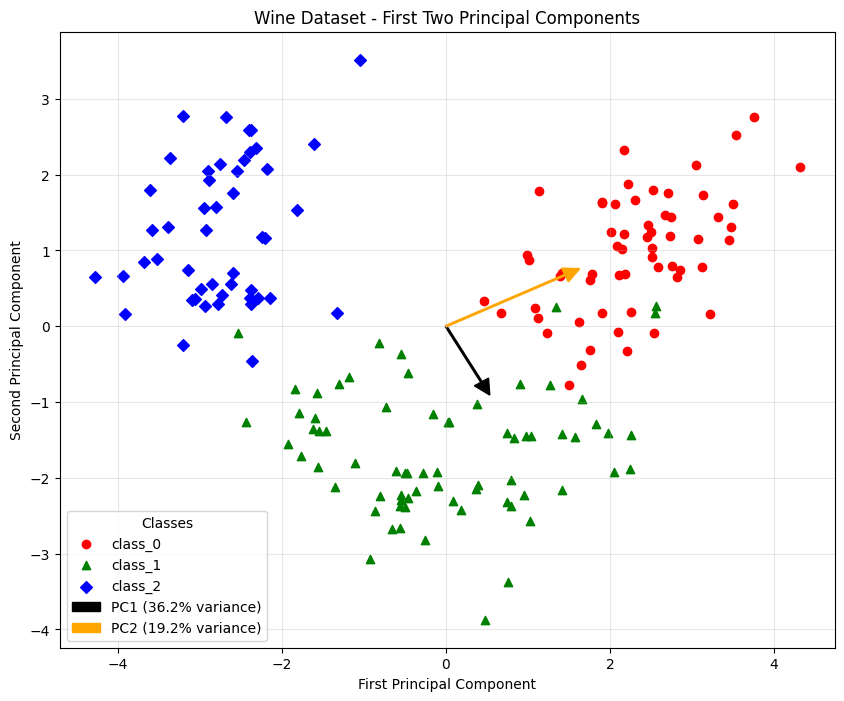

In [4]:
plt.figure(figsize=(10, 8))
shapes = ["o", "^", "D"]
colors = ["r", "g", "b"]

for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(
        X_pca[target_wine == i, 0],
        X_pca[target_wine == i, 1],
        c=color, marker=shape,
        label=wine.target_names[i],
    )

# Ambil komponen PCA dan gambarkan sebagai vektor
pca = pca_pipeline.named_steps["pca"]
origin = np.zeros(2)
arrow_colors = ["black", "orange"]
scaling = 3

for i, (component, ratio) in enumerate(
    zip(pca.components_, pca.explained_variance_ratio_)
):
    plt.arrow(
        origin[0], origin[1],
        component[0] * scaling, component[1] * scaling,
        color=arrow_colors[i], width=0.02,
        head_width=0.2, head_length=0.2,
        label=f"PC{i+1} ({ratio:.1%} variance)",
    )

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("Wine Dataset - First Two Principal Components")
plt.legend(title="Classes")
plt.grid(True, alpha=0.3)
plt.show()

Hanya dengan melihat dua principal component ini, pemisahan antar kelas wine sudah cukup terlihat jelas. LDA, yang memang didesain khusus untuk memisahkan kelas, akan kita bahas sesudah ini.

### Cara Kerja PCA

PCA mencari arah (principal component) di mana data bervariasi paling besar. Komponen-komponen ini adalah kombinasi linear dari fitur asli dan saling tegak lurus (orthogonal) satu sama lain. Langkah-langkah utamanya:

1. **Standardisasi**: karena PCA sensitif terhadap variansi variabel asli, data wajib distandarisasi dulu (mean=0, variance=1).
2. **Perhitungan matriks kovarians**: menangkap seberapa besar tiap dimensi bervariasi terhadap dimensi lain.
3. **Perhitungan eigenvalue dan eigenvector**: eigenvalue menunjukkan besarnya variansi yang ditangkap tiap komponen, eigenvector menunjukkan arahnya.
4. **Pemilihan principal component**: memilih subset komponen berdasarkan eigenvalue-nya untuk mereduksi dimensi sambil mempertahankan sebagian besar variansi.
5. **Transformasi data**: memproyeksikan data asli ke principal component yang terpilih.

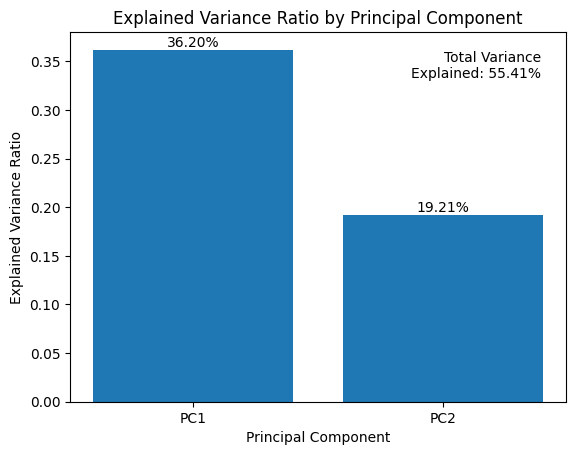

In [5]:
pca = pca_pipeline.named_steps["pca"]
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.sum(explained_variance_ratio)

fig, ax = plt.subplots()
x = np.arange(1, len(explained_variance_ratio) + 1)
y = explained_variance_ratio
bars = ax.bar(x, y)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0, height,
        f"{height:.2%}", ha="center", va="bottom",
    )

ax.text(
    0.95, 0.95,
    f"Total Variance\nExplained: {cumulative_variance:.2%}",
    transform=ax.transAxes, ha="right", va="top",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
)

ax.set_xticks(x)
ax.set_xticklabels(["PC1", "PC2"])
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("Explained Variance Ratio by Principal Component")
plt.show()

Lebih dari separuh total variansi dataset sudah terwakili oleh dua principal component pertama saja. Ini contoh bagus bagaimana PCA bisa memangkas 13 fitur asli wine dataset jadi 2 dimensi tanpa kehilangan terlalu banyak informasi.

## 3. Memaksimalkan Pemisahan Kelas dengan LDA

**Linear Discriminant Analysis (LDA)** adalah teknik dimensionality reduction yang cocok untuk tugas supervised learning, khususnya klasifikasi. Berbeda dari PCA yang memaksimalkan variansi tanpa mempertimbangkan label kelas, LDA justru berusaha memaksimalkan pemisahan antar kelas.

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X_wine, y_wine = wine.data, wine.target

lda_pipeline_wine = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=2)),
])

X_lda_wine = lda_pipeline_wine.fit_transform(X_wine, y_wine)

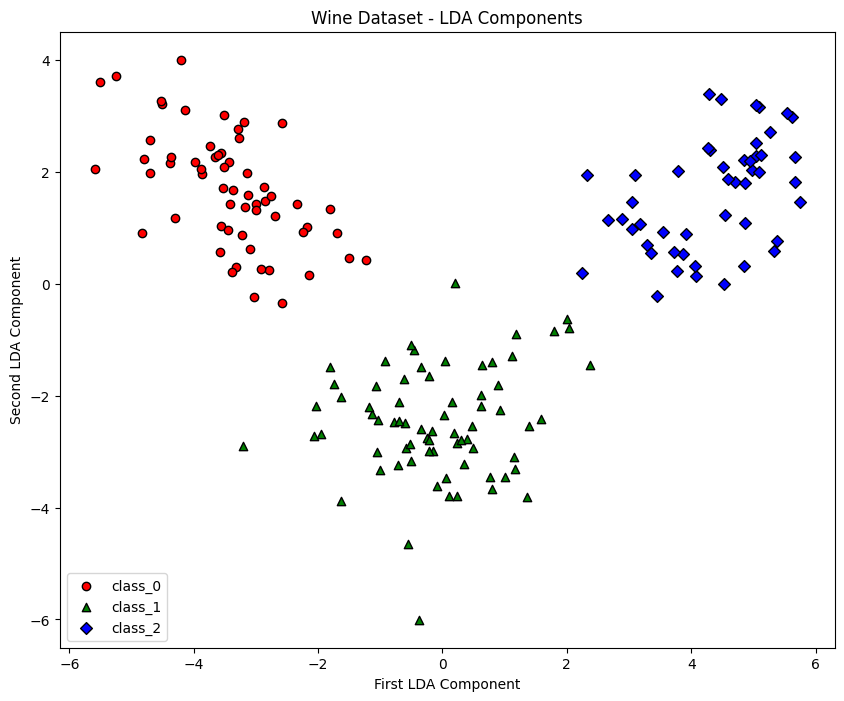

In [7]:
plt.figure(figsize=(10, 8))
shapes = ["o", "^", "D"]
colors = ["r", "g", "b"]

for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_lda_wine[mask, 0], X_lda_wine[mask, 1],
        c=color, marker=shape, edgecolor="black",
        label=wine.target_names[i],
    )

plt.xlabel("First LDA Component")
plt.ylabel("Second LDA Component")
plt.title("Wine Dataset - LDA Components")
plt.legend()
plt.show()

Setelah menerapkan LDA, kita bisa melihat pengelompokan tiga kelas wine jauh lebih rapi dan terpisah dibanding sekadar menggunakan PCA.

### Cara Kerja LDA

LDA adalah teknik supervised yang mencari kombinasi linear fitur yang paling baik memisahkan dua kelas atau lebih. Tujuan utamanya:

- **Memaksimalkan pemisahan kelas**: LDA mencari sumbu yang memaksimalkan jarak antar kelas sambil meminimalkan variansi di dalam tiap kelas.
- **Reduksi dimensi**: dengan memproyeksikan data ke ruang berdimensi lebih rendah yang didefinisikan oleh linear discriminant, LDA mengurangi kompleksitas data sambil mempertahankan informasi penting untuk klasifikasi.
- **Asumsi**: LDA mengasumsikan data tiap kelas mengikuti distribusi Gaussian (normal) dengan matriks kovarians yang sama, intinya tiap fitur punya variansi yang relatif serupa (ini sebabnya kita selalu melakukan standardisasi lebih dulu).

### Perbedaan PCA dan LDA

Meski sama-sama dipakai untuk dimensionality reduction, PCA dan LDA punya tujuan dan metodologi yang berbeda:

| Aspek | PCA | LDA |
|---|---|---|
| Tipe | Unsupervised | Supervised |
| Tujuan | Memaksimalkan variansi | Memaksimalkan pemisahan kelas |
| Output | Principal component (orthogonal) | Linear discriminant |
| Kasus pemakaian | Eksplorasi data, reduksi noise, feature extraction tanpa label | Tugas klasifikasi di mana pemisahan kelas penting |

Mari bandingkan keduanya secara visual berdampingan.

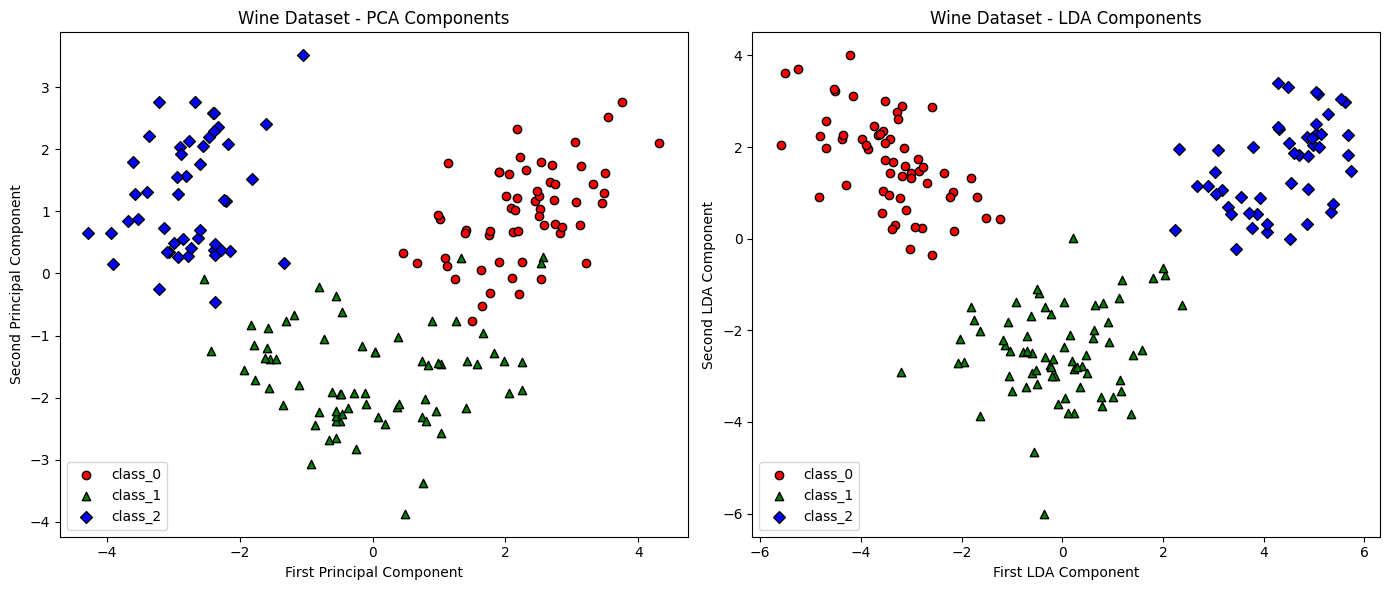

In [8]:
plt.figure(figsize=(14, 6))

plt.subplot(121)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=color, marker=shape, edgecolor="black",
        label=wine.target_names[i],
    )
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("Wine Dataset - PCA Components")
plt.legend()

plt.subplot(122)
for i, (shape, color) in enumerate(zip(shapes, colors)):
    mask = y_wine == i
    plt.scatter(
        X_lda_wine[mask, 0], X_lda_wine[mask, 1],
        c=color, marker=shape, edgecolor="black",
        label=wine.target_names[i],
    )
plt.xlabel("First LDA Component")
plt.ylabel("Second LDA Component")
plt.title("Wine Dataset - LDA Components")
plt.legend()

plt.tight_layout()
plt.show()

Pemisahan kelas memang sedikit lebih jelas lewat LDA, tapi ini wajar karena LDA adalah metode supervised yang memanfaatkan label kelas secara langsung, sesuatu yang tidak dilakukan PCA.

## 4. t-SNE untuk Visualisasi Data

**t-Distributed Stochastic Neighbor Embedding (t-SNE)** adalah teknik untuk memvisualisasikan data berdimensi tinggi dengan memetakannya ke ruang berdimensi rendah (biasanya 2D atau 3D). Teknik ini sangat efektif mengungkap struktur tersembunyi dalam dataset yang kompleks. Kita akan memakai dataset digits (gambar tulisan tangan angka 0-9) untuk demonstrasi ini.

In [9]:
from sklearn.datasets import load_digits

digits = load_digits()
print(f"Jumlah gambar: {digits.data.shape[0]}, jumlah fitur (piksel): {digits.data.shape[1]}")

Jumlah gambar: 1797, jumlah fitur (piksel): 64


In [10]:
from sklearn.manifold import TSNE

tsne_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("tsne", TSNE(n_components=2, random_state=2024)),
])

X_tsne = tsne_pipeline.fit_transform(digits.data)

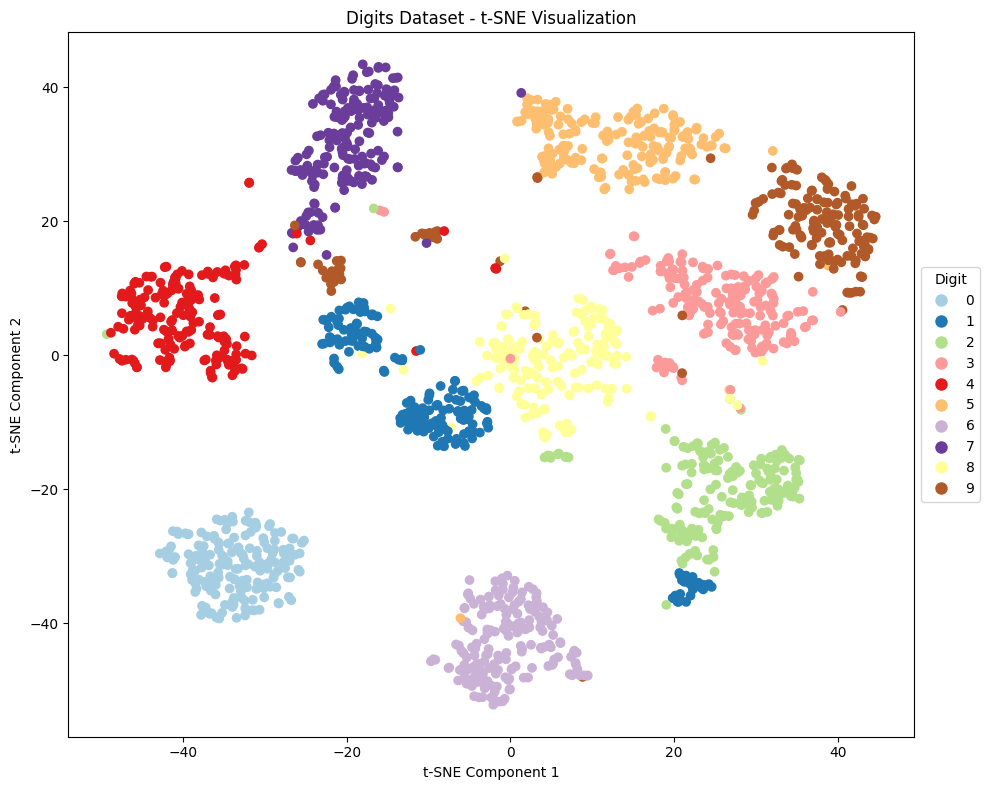

In [11]:
plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=digits.target, cmap="Paired",
)
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Digits Dataset - t-SNE Visualization")

legend_elements = [
    plt.Line2D(
        [0], [0], marker="o", color="w",
        markerfacecolor=plt.cm.Paired(i / 9),
        label=str(i), markersize=10,
    )
    for i in range(10)
]
plt.legend(
    handles=legend_elements, title="Digit",
    loc="center left", bbox_to_anchor=(1, 0.5),
)
plt.tight_layout()
plt.show()

t-SNE unggul dalam memisahkan kelas, bahkan ketika jumlah kelas dan dimensi datanya bertambah besar, di sini sampai 10 kelas angka. Hasil visualisasinya juga cukup masuk akal secara intuitif: beberapa angka "9" terlihat berdekatan dengan "7" dan "4", yang memang mirip bentuk tulisannya tergantung gaya tulisan tangan, sementara angka "0" cenderung terisolasi di satu sudut karena bentuknya cukup berbeda dari angka lain.

### Cara Kerja t-SNE

t-SNE adalah teknik non-linear yang unggul dalam memvisualisasikan data berdimensi tinggi. Caranya: mengonversi jarak Euclidean antar titik data berdimensi tinggi jadi probabilitas kondisional yang merepresentasikan kemiripan. Tahapan utamanya:

1. **Pairwise similarities**: menghitung kemiripan berpasangan antar titik data berdimensi tinggi, memberi probabilitas lebih besar untuk titik yang mirip dan lebih kecil untuk yang berbeda.
2. **Low-dimensional mapping**: mencari representasi berdimensi rendah (2D atau 3D) yang mempertahankan kemiripan ini sebaik mungkin.
3. **Cluster formation**: hasilnya berupa visualisasi di mana titik data yang mirip mengelompok berdekatan, sementara yang berbeda terpisah jauh, efektif mengungkap klaster dalam data.

## 5. Memilih Teknik yang Tepat

Setiap teknik dimensionality reduction punya kelebihan dan konteks pemakaian masing-masing:

- **Supervised vs unsupervised**: kalau data punya label dan tujuannya memaksimalkan pemisahan kelas, LDA jadi pilihan tepat. Untuk data tanpa label di mana kita ingin menangkap variansi tanpa mempertimbangkan label, PCA lebih cocok. t-SNE bisa dipakai untuk visualisasi terlepas dari ada tidaknya label.
- **Variansi vs pemisahan kelas**: kalau tujuannya mempertahankan variansi maksimal, pilih PCA. Kalau fokusnya pada pemisahan kelas untuk klasifikasi, pilih LDA. Untuk memvisualisasikan hubungan dan klaster kompleks, t-SNE unggul.
- **Feature extraction vs visualisasi**: PCA dan LDA lebih sering dipakai untuk feature extraction yang meningkatkan performa model, sementara t-SNE memang didesain khusus untuk visualisasi.
- **Efisiensi komputasi**: PCA relatif efisien dan bisa menangani dataset besar. LDA butuh perhitungan mean dan matriks kovarians tiap kelas, yang bisa kurang efisien untuk data berdimensi sangat tinggi atau jumlah kelas yang banyak. t-SNE bisa cukup berat secara komputasi, apalagi pada dataset besar, karena proses optimasinya bersifat iteratif.
- **Interpretabilitas**: principal component dari PCA kadang sulit diinterpretasikan karena berupa kombinasi linear dari banyak fitur asli. Linear discriminant dari LDA lebih mudah diinterpretasikan dari sisi pemisahan kelas. Hasil t-SNE lebih bersifat visual dan biasanya tidak memberi interpretasi langsung soal kontribusi tiap fitur.

## 6. Dampak terhadap Performa Model

Dimensionality reduction bisa berdampak signifikan terhadap performa model, dengan beberapa trade-off yang perlu dipertimbangkan:

- **Kompleksitas model vs interpretabilitas**: fitur yang lebih sedikit membuat model lebih sederhana dan mudah diinterpretasikan, tapi berisiko kehilangan informasi penting untuk prediksi akurat.
- **Waktu training vs akurasi**: model yang dilatih pada data berdimensi lebih rendah umumnya butuh waktu dan resource komputasi lebih sedikit, tapi kalau fitur penting ikut terbuang, akurasi model bisa menurun.
- **Overfitting vs underfitting**: dimensionality reduction membantu mengurangi overfitting dengan membuang noise dan fitur yang tidak relevan, tapi kalau terlalu banyak dimensi yang dibuang, model justru bisa jadi terlalu sederhana (underfitting) dan gagal menangkap pola penting.

## 7. Latihan Praktis

### Contoh 1: PCA dengan Logistic Regression

Mari kita lihat bagaimana penerapan PCA sebelum melatih model logistic regression memengaruhi performanya, memakai dataset Iris.

In [12]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=2024
)

# Pipeline TANPA PCA
pipeline_tanpa_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=2024)),
])

# Pipeline DENGAN PCA (reduksi ke 2 komponen)
pipeline_dengan_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("clf", LogisticRegression(max_iter=1000, random_state=2024)),
])

pipeline_tanpa_pca.fit(X_train_iris, y_train_iris)
pipeline_dengan_pca.fit(X_train_iris, y_train_iris)

akurasi_tanpa_pca = accuracy_score(
    y_test_iris, pipeline_tanpa_pca.predict(X_test_iris)
)
akurasi_dengan_pca = accuracy_score(
    y_test_iris, pipeline_dengan_pca.predict(X_test_iris)
)

print(f"Akurasi tanpa PCA (4 fitur asli)   : {akurasi_tanpa_pca:.4f}")
print(f"Akurasi dengan PCA (2 komponen)     : {akurasi_dengan_pca:.4f}")

Akurasi tanpa PCA (4 fitur asli)   : 0.9333
Akurasi dengan PCA (2 komponen)     : 0.8333


Dataset Iris hanya punya 4 fitur, jadi tidak mengherankan kalau mereduksinya jadi 2 komponen PCA tidak banyak mengubah akurasi, bahkan kadang hasilnya identik. Manfaat PCA akan lebih terasa pada dataset dengan puluhan atau ratusan fitur, di mana reduksi dimensi benar-benar memangkas kompleksitas komputasi secara signifikan.

### Contoh 2: t-SNE untuk Visualisasi dan K-means

Di contoh kedua, kita memakai t-SNE untuk memvisualisasikan dataset digits, lalu membandingkan hasil clustering K-means terhadap label aslinya untuk melihat seberapa baik struktur yang ditemukan t-SNE selaras dengan label sebenarnya.

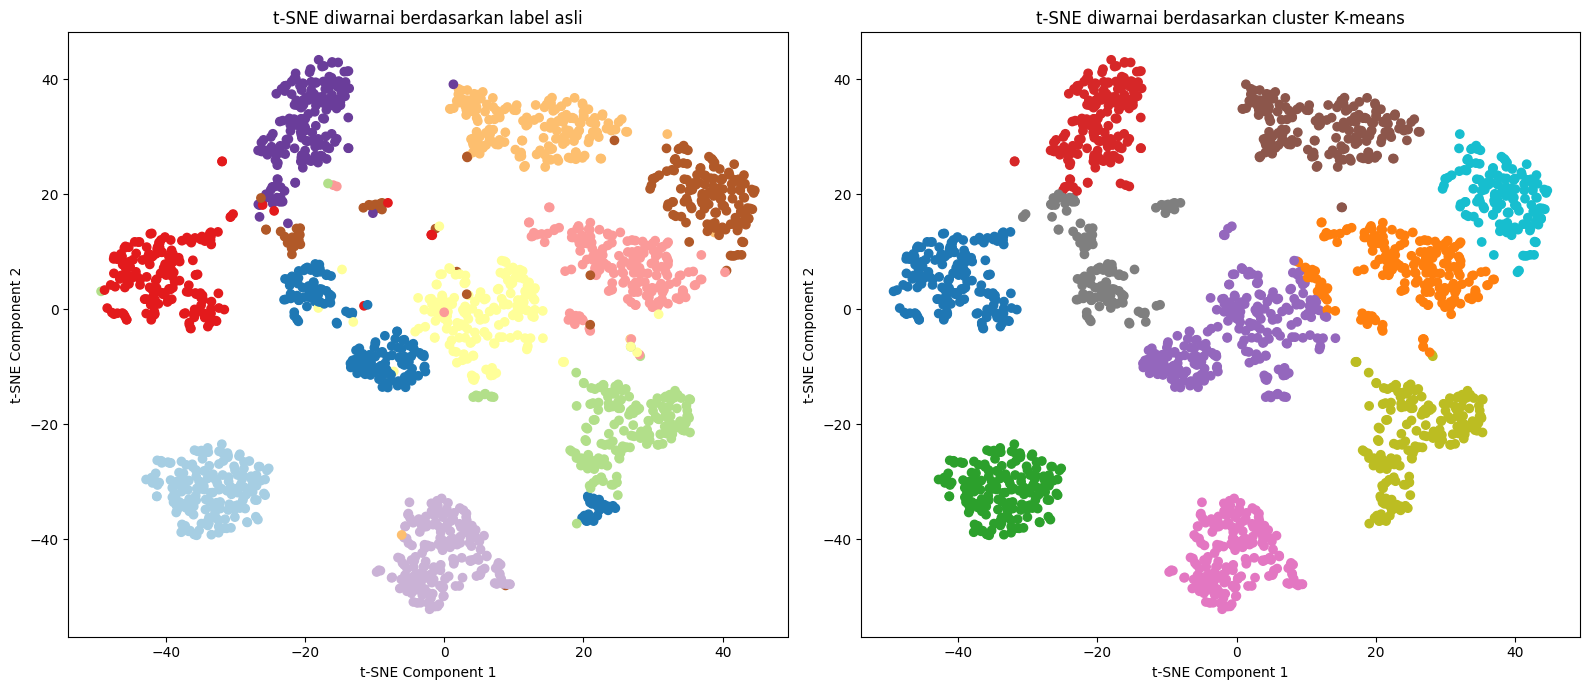

In [13]:
from sklearn.cluster import KMeans

# Terapkan K-means pada data t-SNE
kmeans = KMeans(n_clusters=10, random_state=2024, n_init=10)
cluster_labels = kmeans.fit_predict(X_tsne)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

scatter1 = ax1.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap="Paired")
ax1.set_title("t-SNE diwarnai berdasarkan label asli")
ax1.set_xlabel("t-SNE Component 1")
ax1.set_ylabel("t-SNE Component 2")

scatter2 = ax2.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap="tab10")
ax2.set_title("t-SNE diwarnai berdasarkan cluster K-means")
ax2.set_xlabel("t-SNE Component 1")
ax2.set_ylabel("t-SNE Component 2")

plt.tight_layout()
plt.show()

Kalau kedua plot ini menunjukkan pola pewarnaan yang mirip (walau urutan warnanya bisa berbeda karena K-means tidak tahu angka asli tiap label), itu tanda bahwa struktur klaster yang ditemukan t-SNE memang selaras dengan label sebenarnya, sesuatu yang berguna untuk validasi kualitas clustering di dunia nyata ketika label aslinya tidak tersedia.

## Poin-poin Penting Bab 3

- Dimensionality reduction bertujuan menyederhanakan data, mengurangi biaya komputasi, meningkatkan performa model, dan mempermudah visualisasi, bukan sekadar membuang data secara sembarangan.
- PCA adalah teknik unsupervised yang memaksimalkan variansi, cocok untuk eksplorasi data dan feature extraction tanpa label.
- LDA adalah teknik supervised yang memaksimalkan pemisahan antar kelas, lebih cocok untuk tugas klasifikasi.
- t-SNE unggul untuk visualisasi data berdimensi tinggi dalam 2D atau 3D, tapi hasilnya lebih bersifat eksploratif ketimbang untuk feature extraction langsung ke model.
- Pemilihan teknik yang tepat bergantung pada tujuan (variansi vs pemisahan kelas vs visualisasi), ketersediaan label, ukuran dataset, dan kebutuhan interpretabilitas.
- Dimensionality reduction punya trade-off nyata: kompleksitas model vs interpretabilitas, waktu training vs akurasi, serta risiko overfitting vs underfitting, semuanya perlu dipertimbangkan sebelum diterapkan secara membabi buta.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 3 "Dimensionality Reduction Techniques". Packt Publishing.